# Chapter 45: Derivatives, Options, Insurance, and Contingent Claims

This notebook reruns four worked examples from the chapter: a Black-Scholes-Merton call and its delta hedge, a bottomry loan repaid only if the ship arrives, a hull insurance pool with correlated losses, and a put-call parity arbitrage. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def tie_or_winner(a_name, a_value, b_name, b_value, tol=1e-9, higher_wins=True):
    """Return (winner or 'tie', is_tie). Ties within ``tol`` are reported honestly."""
    if abs(float(a_value) - float(b_value)) <= tol:
        return "tie", True
    a_better = a_value > b_value if higher_wins else a_value < b_value
    return (a_name if a_better else b_name), False


def norm_cdf(x):
    """Standard normal CDF N(x). black-scholes-merton-option-pricing (ch045): N(-0.1414) = 0.4438."""
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))


def bs_call(S, K, T, r, sigma):
    """Black-Scholes-Merton European call. black-scholes-merton-option-pricing (ch045).

    S 80, K 85, T 0.5, r 0.04, sigma 0.25: d1 -0.1414, d2 -0.3182, N(d1) 0.4438, N(d2) 0.3752, C 4.24;
    sigma 0.35: d1 -0.0404, d2 -0.2879, N(d1) 0.4839, C 6.49.
    Returns dict d1, d2, Nd1, Nd2, disc (e^{-rT}), C.
    """
    st = sigma * math.sqrt(T)
    d1 = (math.log(S / K) + (r + sigma ** 2 / 2) * T) / st
    d2 = d1 - st
    disc = math.exp(-r * T)
    n1, n2 = norm_cdf(d1), norm_cdf(d2)
    return {"d1": d1, "d2": d2, "Nd1": n1, "Nd2": n2, "disc": disc, "C": S * n1 - K * disc * n2}


def contingent_repayment(advance, rate, cost, q):
    """Bottomry repayment due only on safe arrival. bottomry-as-options-futures (ch045):
    120,000(1.03) + 3,000 = 126,600; R = 126,600 / 0.75 = 168,800 (211,000 at q 0.60).
    Returns dict required, R."""
    req = advance * (1 + rate) + cost
    return {"required": req, "R": req / q}


def pooled_loss_sd(n, p, loss, rho=0.0):
    """insurance-risk-pooling: average-loss SD of n stores with equal pairwise correlation rho.

    Var(avg) = p(1-p)loss^2 (rho + (1-rho)/n). Book (ch043): n=225, p=0.04, loss=5,000:
    individual variance 960,000, SD 979.80, total SD 14,696.94, average SD 65.32 (rho 0),
    variance 99,840 and SD 315.97 (rho 0.10). Returns a dict.
    """
    var1 = p * (1 - p) * loss * loss
    var_avg = var1 * (rho + (1 - rho) / n)
    return {"expected": p * loss, "var_ind": var1, "sd_ind": math.sqrt(var1),
            "total_sd_indep": math.sqrt(n * var1), "var_avg": var_avg, "sd_avg": math.sqrt(var_avg),
            "floor_sd": math.sqrt(rho * var1)}


def parity_gap(C, P, S, B):
    """Put-call parity gap. put-call-parity (ch045): call 5.20 + bond 48.50 = 53.70,
    put 2.40 + stock 52 = 54.40, gap 0.70. Returns dict call_bond, put_stock, gap (put_stock - call_bond)."""
    cb, ps = C + B, P + S
    return {"call_bond": cb, "put_stock": ps, "gap": ps - cb}


plt.rcParams.update(HOUSE_RC)


finance = SimpleNamespace(norm_cdf=norm_cdf, bs_call=bs_call, contingent_repayment=contingent_repayment, pooled_loss_sd=pooled_loss_sd, parity_gap=parity_gap)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'black-scholes-merton-option-pricing': {'S0': 80,
                                         'K': 85,
                                         'T': 0.5,
                                         'r': 0.04,
                                         'sigma': 0.25,
                                         'd1': -0.1414,
                                         'd2': -0.3182,
                                         'Nd1': 0.4438,
                                         'Nd2': 0.3752,
                                         'C': 4.24,
                                         'calls': 500,
                                         'hedge': 221.9,
                                         'sigma_2': 0.35,
                                         'd1_2': -0.0404,
                                         'd2_2': -0.2879,
                                         'Nd1_2': 0.4839,
                                         'C_2': 6.49,
                                         'change': 2.25},
 'bottomry-as-options-futures': {'advance': 120000,
                                 'rate': 0.03,
                                 'cost': 3000,
                                 'required': 126600,
                                 'q': 0.75,
                                 'R': 168800,
                                 'proceeds': 230000,
                                 'merchant': 45900,
                                 'q_2': 0.6,
                                 'R_2': 211000,
                                 'merchant_2': 11400},
 'maritime-insurance-risk-pricing': {'n': 144,
                                     'indemnity': 750000,
                                     'p': 0.016,
                                     'expected': 12000,
                                     'admin': 2400,
                                     'loading': 1600,
                                     'premium': 16000,
                                     'sd_indep': 7842.19,
                                     'c': 0.08,
                                     'sd_corr': 27659.72,
                                     'ratio': 3.53,
                                     'p_2': 0.01,
                                     'expected_2': 7500,
                                     'premium_2': 11500},
 'put-call-parity': {'S': 52,
                     'K': 50,
                     'call': 5.2,
                     'put': 2.4,
                     'bond': 48.5,
                     'call_bond': 53.7,
                     'put_stock': 54.4,
                     'gap': 0.7},
 'constructed': {'black-scholes-merton-option-pricing': {'sigma': [0.15, 0.45], 'S0': [70, 90]},
                 'bottomry-as-options-futures': {'q': [0.9], 'rate': [0.0, 0.06]},
                 'maritime-insurance-risk-pricing': {'p': [0.025], 'c': [0.04]},
                 'put-call-parity': {'put': [1.7, 3.1], 'ST': [40, 50, 60, 70], 'costs': 0.85}}}


def pct0(x):
    return f"{num(100 * x, 0)}%"


def bs_picture(sigma=0.25, s0=80):
    S0 = s0
    b = BV["black-scholes-merton-option-pricing"]
    K, T, r, calls = b["K"], b["T"], b["r"], b["calls"]
    res = finance.bs_call(S0, K, T, r, sigma)
    hedge = calls * res["Nd1"]
    a = math.log(S0 / K)
    drift = (r + sigma ** 2 / 2) * T
    numer = round(a, 6) + round(drift, 6)
    st = sigma * math.sqrt(T)
    first = round(S0 * res["Nd1"], 4)
    second = round(K * res["disc"] * res["Nd2"], 4)
    grid = np.linspace(55, 105, 240)
    vals = [finance.bs_call(s, K, T, r, sigma)["C"] for s in grid]
    fig, ax = new_figure()
    ax.plot(grid, vals, color=PALETTE["teal"], linewidth=2.2, label=f"call value, sigma = {pct0(sigma)}")
    ax.plot(grid, np.maximum(grid - K, 0), color=PALETTE["grey"], linewidth=1.6, linestyle="dashed",
            label="value at expiry, max(S - 85, 0)")
    tang = np.linspace(S0 - 9, S0 + 9, 20)
    ax.plot(tang, res["C"] + res["Nd1"] * (tang - S0), color=PALETTE["gold"], linewidth=1.8,
            label=f"delta slope N(d1) = {num(res['Nd1'], 4)}")
    ax.legend(loc="upper left", frameon=False)
    mark(ax, S0, res["C"], f"C = {num(res['C'])}", col="navy", dx=-10, dy=12, ha="right")
    ax.set_xlim(55, 105)
    ax.set_ylim(-1, 26)
    ax.set_xlabel("Stock price today S0")
    ax.set_ylabel("Call value")
    metrics = {"d1": num(res["d1"], 4), "d2": num(res["d2"], 4), "N(d1)": num(res["Nd1"], 4),
               "N(d2)": num(res["Nd2"], 4), "Call value C": num(res["C"]),
               "Shares to hedge 500 short calls": num(hedge, 1)}
    steps = [f"ln({S0}/85) = {num(a, 6)}; ({num(r, 2)} + {num(sigma, 2)}^2/2)(0.5) = {num(drift, 6)}",
             f"Numerator = {num(a, 6)} + {num(drift, 6)} = {num(numer, 6)}",
             f"d1 = {num(numer, 6)} / ({num(sigma, 2)} x sqrt(0.5)) = {num(numer, 6)} / {num(st, 6)} = {num(res['d1'], 4)}",
             f"d2 = {num(res['d1'], 6)} - {num(st, 6)} = {num(round(res['d1'], 6) - round(st, 6), 6)}, about {num(res['d2'], 4)}",
             f"C = {S0} x {num(res['Nd1'], 6)} - 85 x e^(-0.02) x {num(res['Nd2'], 6)} = {num(first, 4)} - "
             f"{num(second, 4)} = {num(first - second, 4)}, about {num(res['C'])}",
             f"Hedge = 500 x {num(res['Nd1'], 4)} = {num(hedge, 1)} shares"]
    interp = (f"With S0 = {S0} and sigma = {pct0(sigma)}, d1 = {num(res['d1'], 4)} and d2 = {num(res['d2'], 4)}, so "
              f"N(d1) = {num(res['Nd1'], 4)} and N(d2) = {num(res['Nd2'], 4)}. The call is worth "
              f"{num(first, 4)} - {num(second, 4)} = {num(res['C'])}, and a writer of 500 calls holds "
              f"500 x {num(res['Nd1'], 4)} = {num(hedge, 1)} shares as the opening hedge. Higher volatility lifts "
              f"the curve above the expiry kink because the payoff is convex.")
    alt = (f"Call value against the stock price for volatility {pct0(sigma)}, lying above the expiry payoff "
           f"max(S - 85, 0). At S0 = {S0} the value is {num(res['C'])} and the tangent has slope "
           f"{num(res['Nd1'], 4)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def bottomry_picture(q=0.75, rate=0.03):
    b = BV["bottomry-as-options-futures"]
    adv, cost, proceeds = b["advance"], b["cost"], b["proceeds"]
    res = finance.contingent_repayment(adv, rate, cost, q)
    req, R = res["required"], res["R"]
    keep = proceeds - R
    merchant = q * keep
    fig, ax = new_figure()
    names = ["Lender,\narrives", "Lender,\nlost", "Merchant,\narrives", "Merchant,\nlost", "Merchant,\nexpected"]
    vals = [R, 0, keep, 0, merchant]
    bar_compare(ax, names, vals, colors=["navy", "navy", "teal", "teal", "gold"],
                value_labels=[num(v, 0) for v in vals], ylabel="Units", xlabel="Party and voyage outcome")
    hline(ax, req, f"lender's required expected receipt {num(req, 0)}", col="terracotta", x_frac=0.3)
    metrics = {"Required expected receipt": num(req), "Repayment on arrival R": num(R),
               "Merchant keeps on arrival": num(keep), "Merchant expected proceeds": num(merchant)}
    steps = [f"Required receipt = 120,000 x {num(1 + rate, 2)} + 3,000 = {num(adv * (1 + rate))} + 3,000 = {num(req)}",
             f"R = {num(req)} / {num(q, 2)} = {num(R)}",
             f"On arrival the merchant keeps 230,000 - {num(R)} = {num(keep)}",
             f"Expected proceeds = {num(q, 2)} x {num(keep)} = {num(merchant)}"]
    interp = (f"The lender needs {num(req)} in expectation. Paid only on arrival, with probability {num(q, 2)}, "
              f"that requires R = {num(req)} / {num(q, 2)} = {num(R)}. The merchant keeps 230,000 - {num(R)} = "
              f"{num(keep)} on arrival, worth {num(q, 2)} x {num(keep)} = {num(merchant)} in expectation. A lower "
              f"arrival chance hurts twice: revenue is less likely and the repayment owed on arrival is larger.")
    alt = (f"Bars for the lender and the merchant in the arrival and loss outcomes. With arrival probability "
           f"{num(q, 2)} and time return {pct0(rate)}, the lender receives {num(R, 0)} on arrival and nothing if "
           f"the ship is lost; the merchant's expected proceeds are {num(merchant, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def hull_picture(p=0.016, c=0.0):
    b = BV["maritime-insurance-risk-pricing"]
    n, I, admin, load = b["n"], b["indemnity"], b["admin"], b["loading"]
    expected = p * I
    premium = expected + admin + load
    sd = finance.pooled_loss_sd(n, p, I, c)["sd_avg"]
    sd0 = finance.pooled_loss_sd(n, p, I, 0.0)["sd_avg"]
    ratio = sd / sd0
    pq = p * (1 - p)
    top = 1 + 143 * c
    fig, (ax1, ax2) = new_figure(ncols=2)
    bar_compare(ax1, ["Expected\nclaim", "Admin", "Loading", "Premium"], [expected, admin, load, premium],
                colors=["navy", "grey", "gold", "teal"], value_labels=[num(v, 0) for v in (expected, admin, load, premium)],
                ylabel="Units per vessel", xlabel="Premium component")
    ax1.set_ylim(0, 28_000)
    bar_compare(ax2, ["Independent", f"c = {num(c, 2)}"], [sd0, sd], colors=["navy", "terracotta"],
                value_labels=[num(sd0), num(sd)], ylabel="SD of average claim", xlabel="Dependence")
    ax2.set_ylim(0, 48_000)
    metrics = {"Expected claim pI": num(expected), "Premium": num(premium), "SD, independent": num(sd0),
               "SD at this correlation": num(sd), "Ratio to independent": num(ratio)}
    steps = [f"pI = {num(p, 3)} x 750,000 = {num(expected)}",
             f"Premium = {num(expected)} + 2,400 + 1,600 = {num(premium)}",
             f"p(1 - p) = {num(p, 3)} x {num(1 - p, 3)} = {num(pq, 6)}",
             f"1/144 + {num(c, 2)}(1 - 1/144) = (1 + {num(c, 2)} x 143)/144 = {num(top, 2)}/144",
             f"SD = 750,000 x sqrt({num(pq, 6)} x {num(top, 2)}/144) = {num(sd)}",
             f"Ratio = sqrt({num(top, 2)}) = {num(ratio)}"]
    same = "equals" if c == 0 else "is"
    interp = (f"Expected claims are {num(p, 3)} x 750,000 = {num(expected)}, so the premium is {num(premium)}; "
              f"correlation does not enter it. The SD of average claims {same} {num(sd)}, which is sqrt({num(top, 2)}) "
              f"= {num(ratio)} times the independent level of {num(sd0)}. Frequency moves both the mean and the "
              f"dispersion; dependence moves only the dispersion.")
    alt = (f"Left: premium {num(premium, 0)} built from expected claim {num(expected, 0)}, administration 2,400 and "
           f"loading 1,600. Right: SD of average claims {num(sd0)} if independent and {num(sd)} at correlation "
           f"{num(c, 2)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def parity_picture(put=2.40, st=60):
    ST = st
    b = BV["put-call-parity"]
    C, S, B, K = b["call"], b["S"], b["bond"], b["K"]
    res = finance.parity_gap(C, put, S, B)
    winner, tie = tie_or_winner("put and stock", res["put_stock"], "call and bond", res["call_bond"])
    gap = abs(res["gap"])
    if tie:
        trade = "Neither: the packages cost the same, so there is nothing to trade"
    elif winner == "put and stock":
        trade = "Buy the call and bond, short the put and the share"
    else:
        trade = "Buy the put and share, short the call and the bond"
    cb_pay = max(ST - K, 0) + K
    ps_pay = max(K - ST, 0) + ST
    grid = np.linspace(30, 85, 200)
    fig, ax = new_figure()
    ax.plot(grid, np.maximum(grid - K, 0) + K, color=PALETTE["navy"], linewidth=3.2, label="call + bond payoff")
    ax.plot(grid, np.maximum(K - grid, 0) + grid, color=PALETTE["gold"], linewidth=1.8, linestyle="dashed",
            label="put + stock payoff")
    ax.plot(grid, np.zeros_like(grid), color=PALETTE["terracotta"], linewidth=1.8, label="net of the two legs")
    ax.legend(loc="center right", frameon=False)
    vline(ax, ST, None, col="grey")
    mark(ax, ST, cb_pay, f"both pay {num(cb_pay)}", col="ink", dx=8, dy=-12, va="top")
    ax.set_xlim(30, 85)
    ax.set_ylim(-5, 90)
    ax.set_xlabel("Stock price at expiry S_T")
    ax.set_ylabel("Payoff at expiry")
    metrics = {"Call + bond cost": num(res["call_bond"]), "Put + stock cost": num(res["put_stock"]),
               "Opening receipt": num(gap), "Payoff of each package at S_T": num(cb_pay), "Terminal net": num(0),
               "Trade": "none" if tie else "buy the cheaper, sell the dearer"}
    if ST > K:
        branch = f"S_T = {ST} > 50: call + bond pay ({ST} - 50) + 50 = {num(cb_pay)}; the put expires and the share costs {ST}"
    else:
        branch = f"S_T = {ST} <= 50: the call expires, the bond pays 50; put + stock pay (50 - {ST}) + {ST} = {num(ps_pay)}"
    steps = [f"Call + bond = 5.20 + 48.50 = {num(res['call_bond'])}",
             f"Put + stock = {num(put)} + 52 = {num(res['put_stock'])}",
             f"Gap = {num(res['put_stock'])} - {num(res['call_bond'])} = {num(res['put_stock'] - res['call_bond'])}",
             branch,
             f"Terminal net = {num(cb_pay)} - {num(ps_pay)} = {num(cb_pay - ps_pay)}"]
    interp = (f"The call and bond cost 5.20 + 48.50 = {num(res['call_bond'])}; the put and stock cost "
              f"{num(put)} + 52 = {num(res['put_stock'])}. "
              f"{trade}" + ("." if tie else f", collecting {num(gap)} today.") +
              f" At S_T = {ST} both packages pay {num(cb_pay)}, so the terminal net is zero"
              + (" and there is no profit to lock in." if tie else
                 " and the opening difference is the whole profit before trading and financing costs."))
    alt = (f"Payoffs at expiry of call plus bond and of put plus stock, which coincide at max(S_T, 50), with a net "
           f"line at zero. At S_T = {ST} each pays {num(cb_pay)}. With the put at {num(put)} the opening gap is "
           f"{num(gap)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Black-Scholes-Merton option pricing

A European call with $S_0=80$, $K=85$, $T=0.5$, $r=4\%$ and $\sigma=25\%$.

$$C=S_0N(d_1)-Ke^{-rT}N(d_2),\qquad d_1=\frac{\ln(S_0/K)+(r+\sigma^2/2)T}{\sigma\sqrt{T}},\qquad d_2=d_1-\sigma\sqrt{T}$$

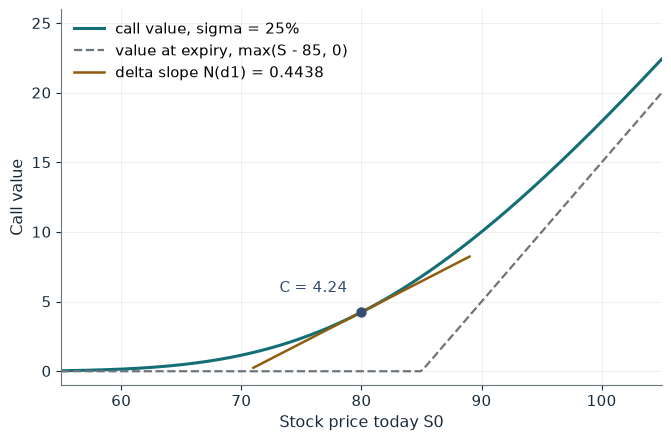

d1                               -0.1414
d2                               -0.3182
N(d1)                            0.4438
N(d2)                            0.3752
Call value C                     4.24
Shares to hedge 500 short calls  221.9

Worked steps:
  1. ln(80/85) = -0.060625; (0.04 + 0.25^2/2)(0.5) = 0.035625
  2. Numerator = -0.060625 + 0.035625 = -0.025000
  3. d1 = -0.025000 / (0.25 x sqrt(0.5)) = -0.025000 / 0.176777 = -0.1414
  4. d2 = -0.141419 - 0.176777 = -0.318196, about -0.3182
  5. C = 80 x 0.443769 - 85 x e^(-0.02) x 0.375168 = 35.5016 - 31.2578 = 4.2438, about 4.24
  6. Hedge = 500 x 0.4438 = 221.9 shares

With S0 = 80 and sigma = 25%, d1 = -0.1414 and d2 = -0.3182, so N(d1) = 0.4438 and N(d2) = 0.3752. The call is worth 35.5016 - 31.2578 = 4.24, and a writer of 500 calls holds 500 x 0.4438 = 221.9 shares as the opening hedge. Higher volatility lifts the curve above the expiry kink because the payoff is convex.


In [2]:
show(bs_picture(sigma=0.25, s0=80))

Change one input, `sigma`, and hold the others at the book's values:

In [3]:
sweep(bs_picture, 'sigma', [0.15, 0.25, 0.35, 0.45], {'s0': 80}, ['d1', 'N(d1)', 'Call value C', 'Shares to hedge 500 short calls'])

sigma | d1 | N(d1) | Call value C | Shares to hedge 500 short calls
0.15 | -0.3300 | 0.3707 | 2.05 | 185.4
0.25 | -0.1414 | 0.4438 | 4.24 | 221.9
0.35 | -0.0404 | 0.4839 | 6.49 | 241.9
0.45 | 0.0314 | 0.5125 | 8.75 | 256.3


At 25% volatility the call is worth 4.24 and 500 short calls are hedged with 221.9 shares. At 35% the value is 6.49, 2.25 higher, and the hedge grows to 241.9 shares.

## 2. Bottomry loans as options and futures

An advance of 120,000, a 3% time return and 3,000 of cost; the ship arrives with probability $q$.

$$R=\frac{L(1+r)+k}{q},\qquad R=\frac{126{,}600}{0.75}=168{,}800$$

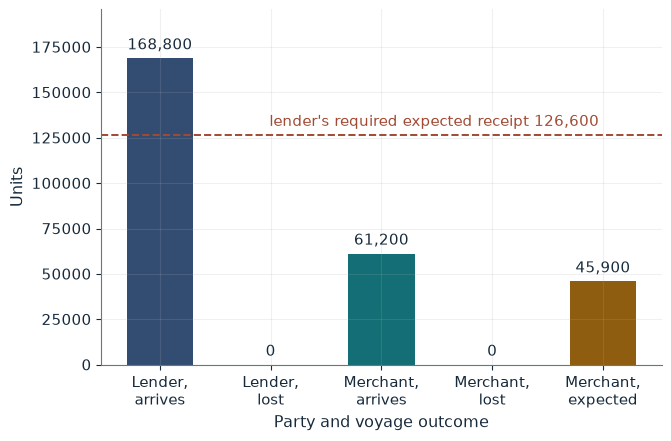

Required expected receipt   126,600.00
Repayment on arrival R      168,800.00
Merchant keeps on arrival   61,200.00
Merchant expected proceeds  45,900.00

Worked steps:
  1. Required receipt = 120,000 x 1.03 + 3,000 = 123,600.00 + 3,000 = 126,600.00
  2. R = 126,600.00 / 0.75 = 168,800.00
  3. On arrival the merchant keeps 230,000 - 168,800.00 = 61,200.00
  4. Expected proceeds = 0.75 x 61,200.00 = 45,900.00

The lender needs 126,600.00 in expectation. Paid only on arrival, with probability 0.75, that requires R = 126,600.00 / 0.75 = 168,800.00. The merchant keeps 230,000 - 168,800.00 = 61,200.00 on arrival, worth 0.75 x 61,200.00 = 45,900.00 in expectation. A lower arrival chance hurts twice: revenue is less likely and the repayment owed on arrival is larger.


In [4]:
show(bottomry_picture(q=0.75, rate=0.03))

Change one input, `q`, and hold the others at the book's values:

In [5]:
sweep(bottomry_picture, 'q', [0.6, 0.75, 0.9], {'rate': 0.03}, ['Repayment on arrival R', 'Merchant expected proceeds'])

q | Repayment on arrival R | Merchant expected proceeds
0.6 | 211,000.00 | 11,400.00
0.75 | 168,800.00 | 45,900.00
0.9 | 140,666.67 | 80,400.00


At $q=0.75$ the merchant repays 168,800 on arrival and expects 45,900. At 0.60 the repayment is 211,000 and the expectation only 11,400: a lower arrival chance hurts twice.

## 3. Maritime insurance and risk pricing

144 vessels, indemnity 750,000, administration 2,400 and loading 1,600.

$$\pi=pI+a+\rho,\qquad \mathrm{SD}=I\sqrt{p(1-p)\left[\frac{1}{N}+c\left(1-\frac{1}{N}\right)\right]}$$

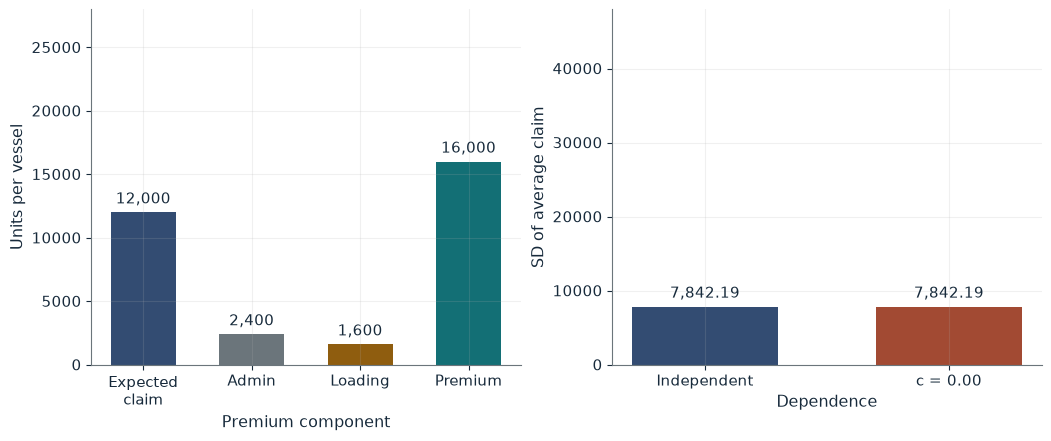

Expected claim pI       12,000.00
Premium                 16,000.00
SD, independent         7,842.19
SD at this correlation  7,842.19
Ratio to independent    1.00

Worked steps:
  1. pI = 0.016 x 750,000 = 12,000.00
  2. Premium = 12,000.00 + 2,400 + 1,600 = 16,000.00
  3. p(1 - p) = 0.016 x 0.984 = 0.015744
  4. 1/144 + 0.00(1 - 1/144) = (1 + 0.00 x 143)/144 = 1.00/144
  5. SD = 750,000 x sqrt(0.015744 x 1.00/144) = 7,842.19
  6. Ratio = sqrt(1.00) = 1.00

Expected claims are 0.016 x 750,000 = 12,000.00, so the premium is 16,000.00; correlation does not enter it. The SD of average claims equals 7,842.19, which is sqrt(1.00) = 1.00 times the independent level of 7,842.19. Frequency moves both the mean and the dispersion; dependence moves only the dispersion.


In [6]:
show(hull_picture(p=0.016, c=0.0))

Change one input, `c`, and hold the others at the book's values:

In [7]:
sweep(hull_picture, 'c', [0.0, 0.04, 0.08], {'p': 0.016}, ['Premium', 'SD at this correlation', 'Ratio to independent'])

c | Premium | SD at this correlation | Ratio to independent
0.0 | 16,000.00 | 7,842.19 | 1.00
0.04 | 16,000.00 | 20,329.29 | 2.59
0.08 | 16,000.00 | 27,659.72 | 3.53


The premium stays at 16,000 whatever the correlation, while the SD of average claims rises from 7,842.19 to 27,659.72 at $c=0.08$, about 3.53 times.

## 4. Put-call parity

Stock 52, call 5.20 (strike 50), put 2.40, bond paying 50 for 48.50.

$$C_0+Ke^{-rT}=P_0+S_0,\qquad 5.20+48.50=53.70,\qquad 2.40+52=54.40$$

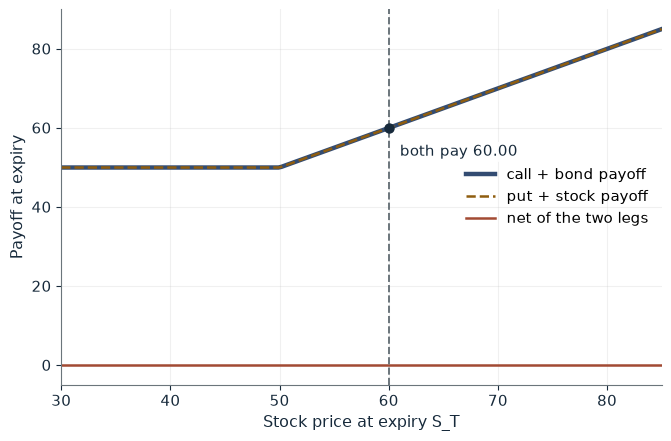

Call + bond cost               53.70
Put + stock cost               54.40
Opening receipt                0.70
Payoff of each package at S_T  60.00
Terminal net                   0.00
Trade                          buy the cheaper, sell the dearer

Worked steps:
  1. Call + bond = 5.20 + 48.50 = 53.70
  2. Put + stock = 2.40 + 52 = 54.40
  3. Gap = 54.40 - 53.70 = 0.70
  4. S_T = 60 > 50: call + bond pay (60 - 50) + 50 = 60.00; the put expires and the share costs 60
  5. Terminal net = 60.00 - 60.00 = 0.00

The call and bond cost 5.20 + 48.50 = 53.70; the put and stock cost 2.40 + 52 = 54.40. Buy the call and bond, short the put and the share, collecting 0.70 today. At S_T = 60 both packages pay 60.00, so the terminal net is zero and the opening difference is the whole profit before trading and financing costs.


In [8]:
show(parity_picture(put=2.40, st=60))

Change one input, `put`, and hold the others at the book's values:

In [9]:
sweep(parity_picture, 'put', [1.7, 2.4, 3.1], {'st': 60}, ['Call + bond cost', 'Put + stock cost', 'Opening receipt', 'Trade'])

put | Call + bond cost | Put + stock cost | Opening receipt | Trade
1.7 | 53.70 | 53.70 | 0.00 | none
2.4 | 53.70 | 54.40 | 0.70 | buy the cheaper, sell the dearer
3.1 | 53.70 | 55.10 | 1.40 | buy the cheaper, sell the dearer


Selling the dearer put and stock and buying the call and bond collects 0.70 today; both packages pay max(S_T, 50), so nothing is owed at expiry. At a put of 1.70 the gap is zero.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

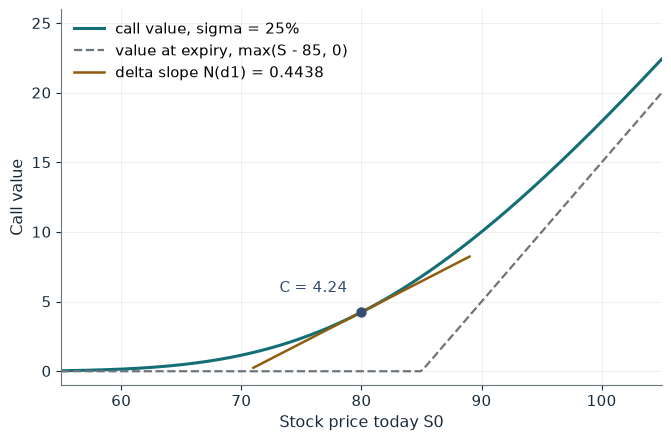

d1                               -0.1414
d2                               -0.3182
N(d1)                            0.4438
N(d2)                            0.3752
Call value C                     4.24
Shares to hedge 500 short calls  221.9

Worked steps:
  1. ln(80/85) = -0.060625; (0.04 + 0.25^2/2)(0.5) = 0.035625
  2. Numerator = -0.060625 + 0.035625 = -0.025000
  3. d1 = -0.025000 / (0.25 x sqrt(0.5)) = -0.025000 / 0.176777 = -0.1414
  4. d2 = -0.141419 - 0.176777 = -0.318196, about -0.3182
  5. C = 80 x 0.443769 - 85 x e^(-0.02) x 0.375168 = 35.5016 - 31.2578 = 4.2438, about 4.24
  6. Hedge = 500 x 0.4438 = 221.9 shares

With S0 = 80 and sigma = 25%, d1 = -0.1414 and d2 = -0.3182, so N(d1) = 0.4438 and N(d2) = 0.3752. The call is worth 35.5016 - 31.2578 = 4.24, and a writer of 500 calls holds 500 x 0.4438 = 221.9 shares as the opening hedge. Higher volatility lifts the curve above the expiry kink because the payoff is convex.


In [10]:
show(bs_picture(sigma=0.25, s0=80))

## Practice

**1.** At sigma 35%, how many shares hedge 500 short calls?

<details><summary>Answer</summary>

N(d1) = 0.4839, so 500 x 0.4839 = 241.9 shares.

</details>

**2.** In the bottomry loan with q = 0.90 and a 3% return, what are R and the merchant's expected proceeds?

<details><summary>Answer</summary>

R = 126,600 / 0.90 = 140,666.67; proceeds 0.90 x (230,000 - 140,666.67) = 80,400.

</details>

**3.** With p = 0.01 and independent losses, what are the premium and the SD of average claims?

<details><summary>Answer</summary>

Premium 7,500 + 2,400 + 1,600 = 11,500; SD = 750,000 x sqrt(0.0099/144) = 6,218.67.

</details>